In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 1. CARREGAMENTO DA BASE OURO
caminho_base = '/home/bruno/UESC/DataSUS/DadosTUB/data/processed/tuberculose_10_cidades_final.csv'
df = pd.read_csv(caminho_base, low_memory=False)

### Adicionando mais cidades à nossa análise

#### São Paulo, Rio de Janeiro, Salvador, Recife, Curitiba, Aracaju, Feira de Santana, Vitória da Conquista.

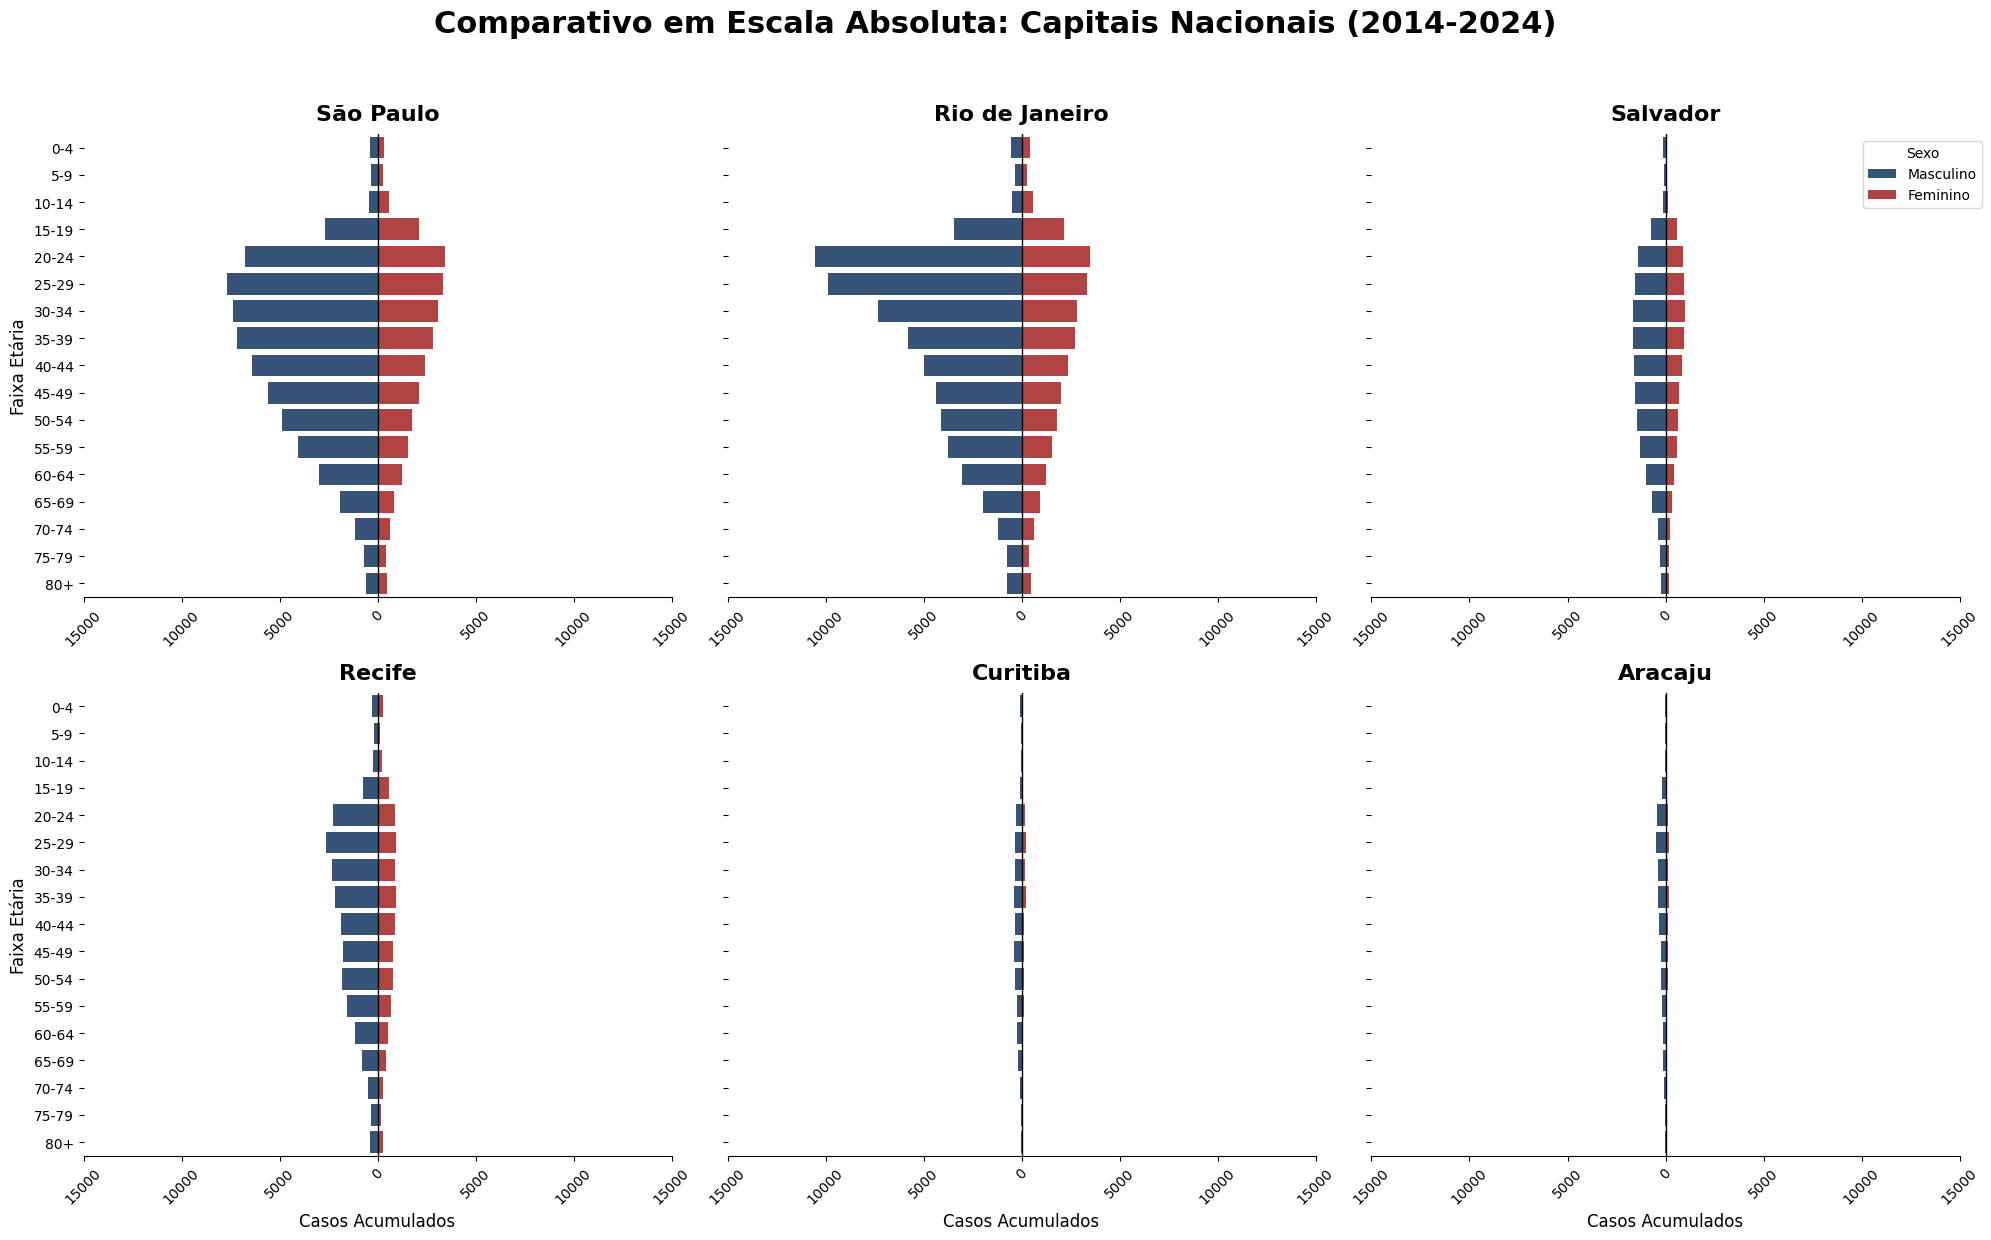

In [17]:
caminho_base = '/home/bruno/UESC/DataSUS/DadosTUB/data/processed/tuberculose_10_cidades_final.csv'
df = pd.read_csv(caminho_base, low_memory=False)
df['Idade_Anos'] = pd.to_numeric(df['Idade_Anos'], errors='coerce')

bins = list(range(0, 85, 5)) + [120]
labels = [f'{i}-{i+4}' for i in range(0, 80, 5)] + ['80+']
df['Faixa_Etaria'] = pd.cut(df['Idade_Anos'], bins=bins, labels=labels, right=False)
df_piramide = df.dropna(subset=['Faixa_Etaria', 'Sexo']).copy()

# ==============================================================================
# PAINEL 1: CAPITAIS (Grid 2 Linhas x 3 Colunas)
# ==============================================================================
capitais = ['São Paulo', 'Rio de Janeiro', 'Salvador', 'Recife', 'Curitiba', 'Aracaju']
df_capitais = df_piramide[df_piramide['Cidade'].isin(capitais)]

# DESCOBRINDO O MAIOR VALOR GLOBAL DAS CAPITAIS PARA TRAVAR O EIXO X
piramide_geral_capitais = df_capitais.groupby(['Cidade', 'Faixa_Etaria', 'Sexo'], observed=False).size().reset_index(name='Casos')
limite_global_capitais = piramide_geral_capitais['Casos'].max() * 1.1 # 10% de margem de respiro

# Criando figura 2x3 bem espaçada
fig, axes = plt.subplots(2, 3, figsize=(20, 12), sharey=True)
axes = axes.flatten()

for i, cidade in enumerate(capitais):
    ax = axes[i]
    df_cidade = df_capitais[df_capitais['Cidade'] == cidade]
    
    if not df_cidade.empty:
        piramide = df_cidade.groupby(['Faixa_Etaria', 'Sexo'], observed=False).size().reset_index(name='Casos')
        piramide.loc[piramide['Sexo'] == 'Masculino', 'Casos'] *= -1
        
        sns.barplot(x='Casos', y='Faixa_Etaria', data=piramide[piramide['Sexo'] == 'Masculino'], 
                    color='#2c5282', label='Masculino', ax=ax, errorbar=None)
        sns.barplot(x='Casos', y='Faixa_Etaria', data=piramide[piramide['Sexo'] == 'Feminino'], 
                    color='#c53030', label='Feminino', ax=ax, errorbar=None)

        # APLICA A REGRA DE OURO: Todos os gráficos terão a mesma largura do maior gráfico
        ax.set_xlim(-limite_global_capitais, limite_global_capitais)

        # Formatação dos números do eixo X
        ticks = ax.get_xticks()
        ax.set_xticks(ticks)
        ax.set_xticklabels([int(abs(x)) for x in ticks], rotation=45)
        
    ax.set_title(f'{cidade}', fontsize=16, fontweight='bold', pad=10)
    ax.axvline(0, color='black', linewidth=1)
    
    # Textos dos eixos apenas nas bordas externas do grid
    ax.set_xlabel('Casos Acumulados' if i >= 3 else '', fontsize=12)
    ax.set_ylabel('Faixa Etária' if i % 3 == 0 else '', fontsize=12)
    
    # Tratamento da Legenda
    if ax.get_legend(): ax.legend_.remove()
    if i == 2: # Coloca a legenda no canto superior direito do grid
        ax.legend(title='Sexo', loc='upper right', bbox_to_anchor=(1.05, 1))

plt.suptitle('Comparativo em Escala Absoluta: Capitais Nacionais (2014-2024)', fontsize=22, fontweight='bold', y=1.03)
sns.despine(left=True)
plt.tight_layout()
plt.show()

### Com base nas estimativas mais recentes do IBGE, a população aproximada dessas capitais é:

#### São Paulo (SP): 11.904.961 habitantes
#### Rio de Janeiro (RJ): 6.730.729 habitantes
#### Salvador (BA): 2.564.204 habitantes
#### Curitiba (PR): 1.830.795 habitantes
#### Recife (PE): 1.588.376 habitantes
#### Aracaju (SE): 630.932 habitantes

### Vamos separar esses gráficos por parâmetros melhores para possibilitar a análise

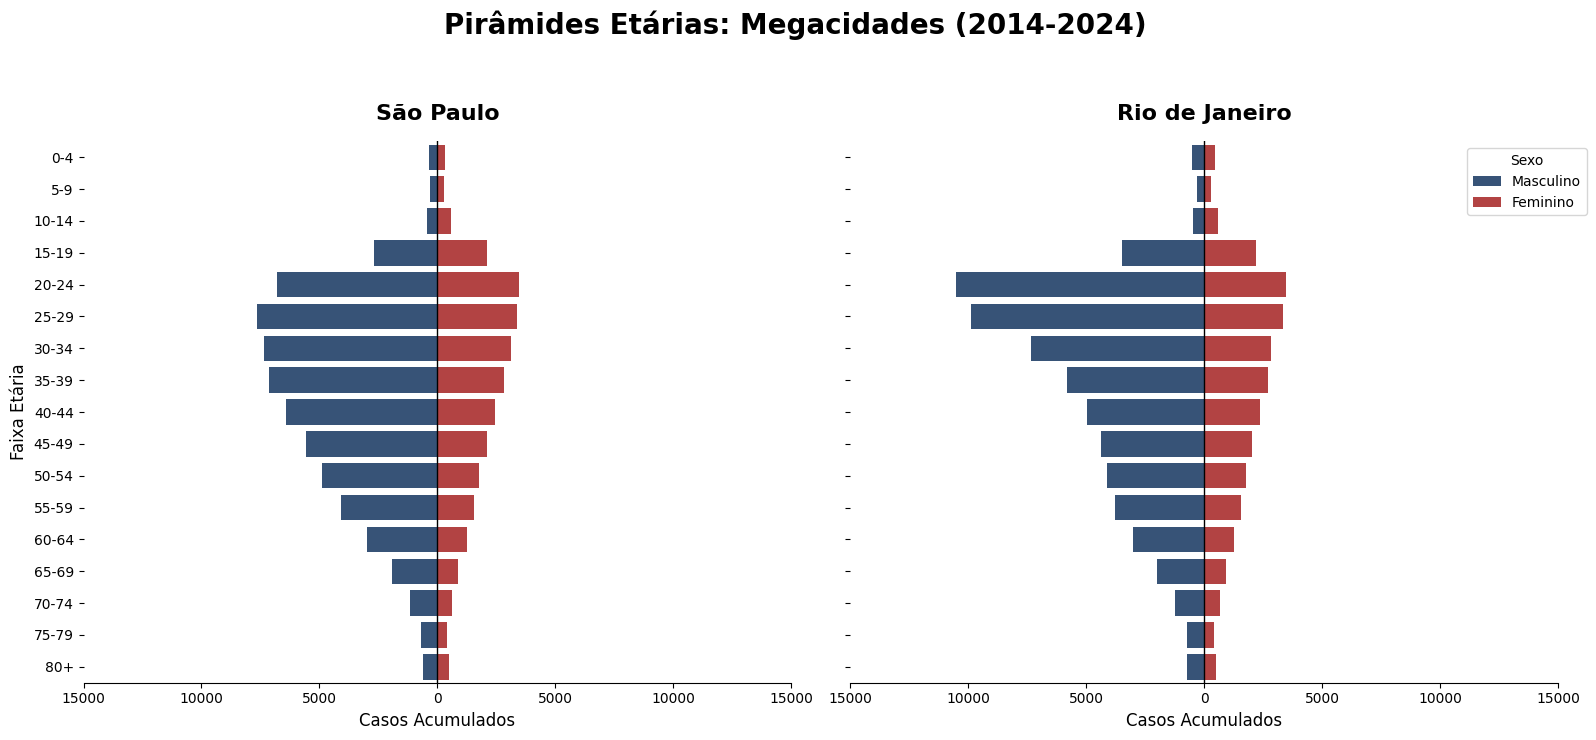

In [8]:
# ==============================================================================
# PAINEL 1: MEGACIDADES (São Paulo e Rio de Janeiro)
# ==============================================================================
megacidades = ['São Paulo', 'Rio de Janeiro']
df_mega = df_piramide[df_piramide['Cidade'].isin(megacidades)]

# Calcula o limite máximo exclusivo para SP e RJ
piramide_geral_mega = df_mega.groupby(['Cidade', 'Faixa_Etaria', 'Sexo'], observed=False).size().reset_index(name='Casos')
limite_global_mega = piramide_geral_mega['Casos'].max() * 1.1

# Grid 1x2 (Lado a lado, bem espaçado)
fig, axes = plt.subplots(1, 2, figsize=(16, 7), sharey=True)

for i, cidade in enumerate(megacidades):
    ax = axes[i]
    df_cidade = df_mega[df_mega['Cidade'] == cidade]
    
    if not df_cidade.empty:
        piramide = df_cidade.groupby(['Faixa_Etaria', 'Sexo'], observed=False).size().reset_index(name='Casos')
        piramide.loc[piramide['Sexo'] == 'Masculino', 'Casos'] *= -1
        
        sns.barplot(x='Casos', y='Faixa_Etaria', data=piramide[piramide['Sexo'] == 'Masculino'], 
                    color='#2c5282', label='Masculino', ax=ax, errorbar=None)
        sns.barplot(x='Casos', y='Faixa_Etaria', data=piramide[piramide['Sexo'] == 'Feminino'], 
                    color='#c53030', label='Feminino', ax=ax, errorbar=None)

        # Aplica a escala gigante exclusiva destas duas cidades
        ax.set_xlim(-limite_global_mega, limite_global_mega)

        ticks = ax.get_xticks()
        ax.set_xticks(ticks)
        ax.set_xticklabels([int(abs(x)) for x in ticks])
        
    ax.set_title(f'{cidade}', fontsize=16, fontweight='bold', pad=15)
    ax.axvline(0, color='black', linewidth=1)
    
    ax.set_xlabel('Casos Acumulados', fontsize=12)
    ax.set_ylabel('Faixa Etária' if i == 0 else '', fontsize=12)
    
    if ax.get_legend(): ax.legend_.remove()
    if i == 1:
        ax.legend(title='Sexo', loc='upper right', bbox_to_anchor=(1.05, 1))

plt.suptitle('Pirâmides Etárias: Megacidades (2014-2024)', fontsize=20, fontweight='bold', y=1.05)
sns.despine(left=True)
plt.tight_layout()
plt.show()

### São Paulo e Rio de Janeiro tem um número de casos muito dipareo por sua população maior, então separamos elas das outras capitais

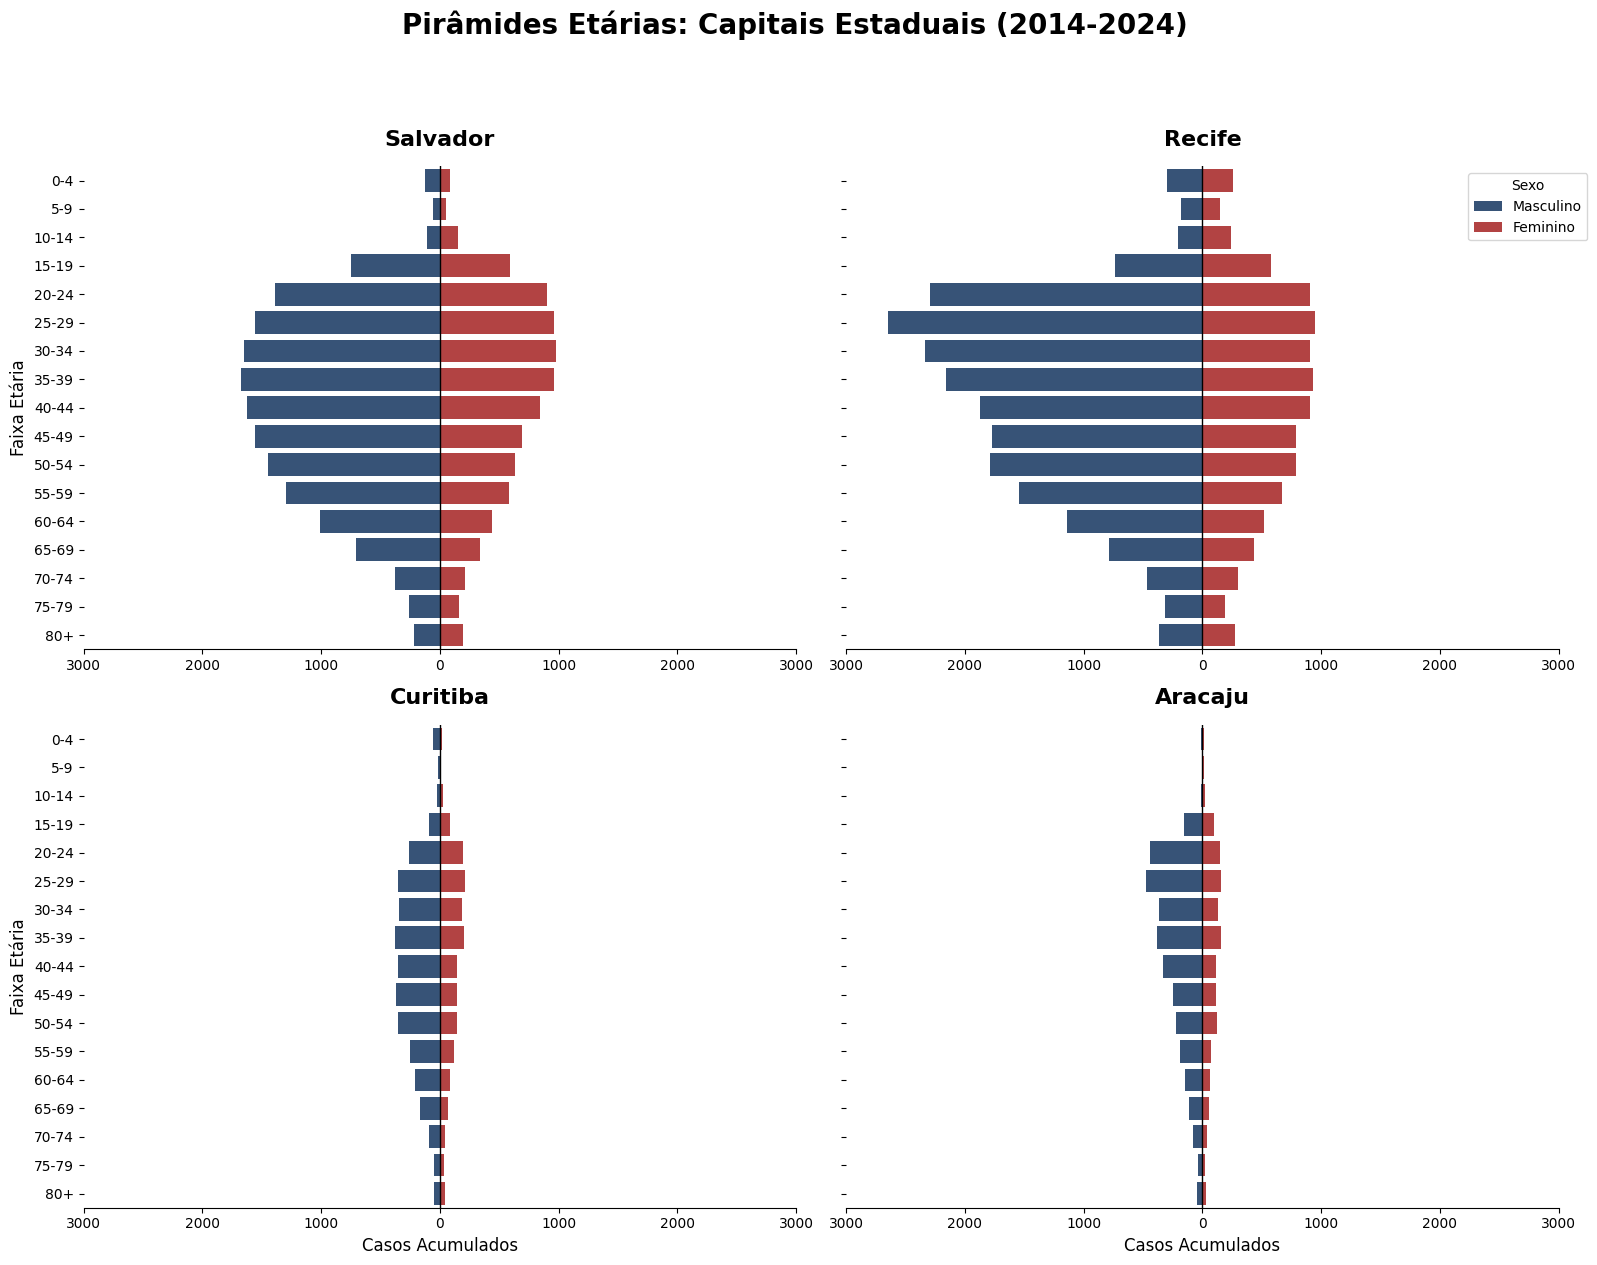

In [9]:
# ==============================================================================
# PAINEL 2: CAPITAIS ESTADUAIS (Salvador, Recife, Curitiba, Aracaju)
# ==============================================================================
capitais_estaduais = ['Salvador', 'Recife', 'Curitiba', 'Aracaju']
df_capitais = df_piramide[df_piramide['Cidade'].isin(capitais_estaduais)]

# Calcula o limite máximo ajustado para a realidade dessas 4 cidades
piramide_geral_cap = df_capitais.groupby(['Cidade', 'Faixa_Etaria', 'Sexo'], observed=False).size().reset_index(name='Casos')
limite_global_cap = piramide_geral_cap['Casos'].max() * 1.1

# Grid 2x2 (Quadrado, maximiza a visibilidade)
fig, axes = plt.subplots(2, 2, figsize=(16, 12), sharey=True)
axes = axes.flatten()

for i, cidade in enumerate(capitais_estaduais):
    ax = axes[i]
    df_cidade = df_capitais[df_capitais['Cidade'] == cidade]
    
    if not df_cidade.empty:
        piramide = df_cidade.groupby(['Faixa_Etaria', 'Sexo'], observed=False).size().reset_index(name='Casos')
        piramide.loc[piramide['Sexo'] == 'Masculino', 'Casos'] *= -1
        
        sns.barplot(x='Casos', y='Faixa_Etaria', data=piramide[piramide['Sexo'] == 'Masculino'], 
                    color='#2c5282', label='Masculino', ax=ax, errorbar=None)
        sns.barplot(x='Casos', y='Faixa_Etaria', data=piramide[piramide['Sexo'] == 'Feminino'], 
                    color='#c53030', label='Feminino', ax=ax, errorbar=None)

        # Aplica a escala adequada
        ax.set_xlim(-limite_global_cap, limite_global_cap)

        ticks = ax.get_xticks()
        ax.set_xticks(ticks)
        ax.set_xticklabels([int(abs(x)) for x in ticks])
        
    ax.set_title(f'{cidade}', fontsize=16, fontweight='bold', pad=15)
    ax.axvline(0, color='black', linewidth=1)
    
    ax.set_xlabel('Casos Acumulados' if i >= 2 else '', fontsize=12)
    ax.set_ylabel('Faixa Etária' if i % 2 == 0 else '', fontsize=12)
    
    if ax.get_legend(): ax.legend_.remove()
    if i == 1:
        ax.legend(title='Sexo', loc='upper right', bbox_to_anchor=(1.05, 1))

plt.suptitle('Pirâmides Etárias: Capitais Estaduais (2014-2024)', fontsize=20, fontweight='bold', y=1.05)
sns.despine(left=True)
plt.tight_layout()
plt.show()

### Cidades da Bahia

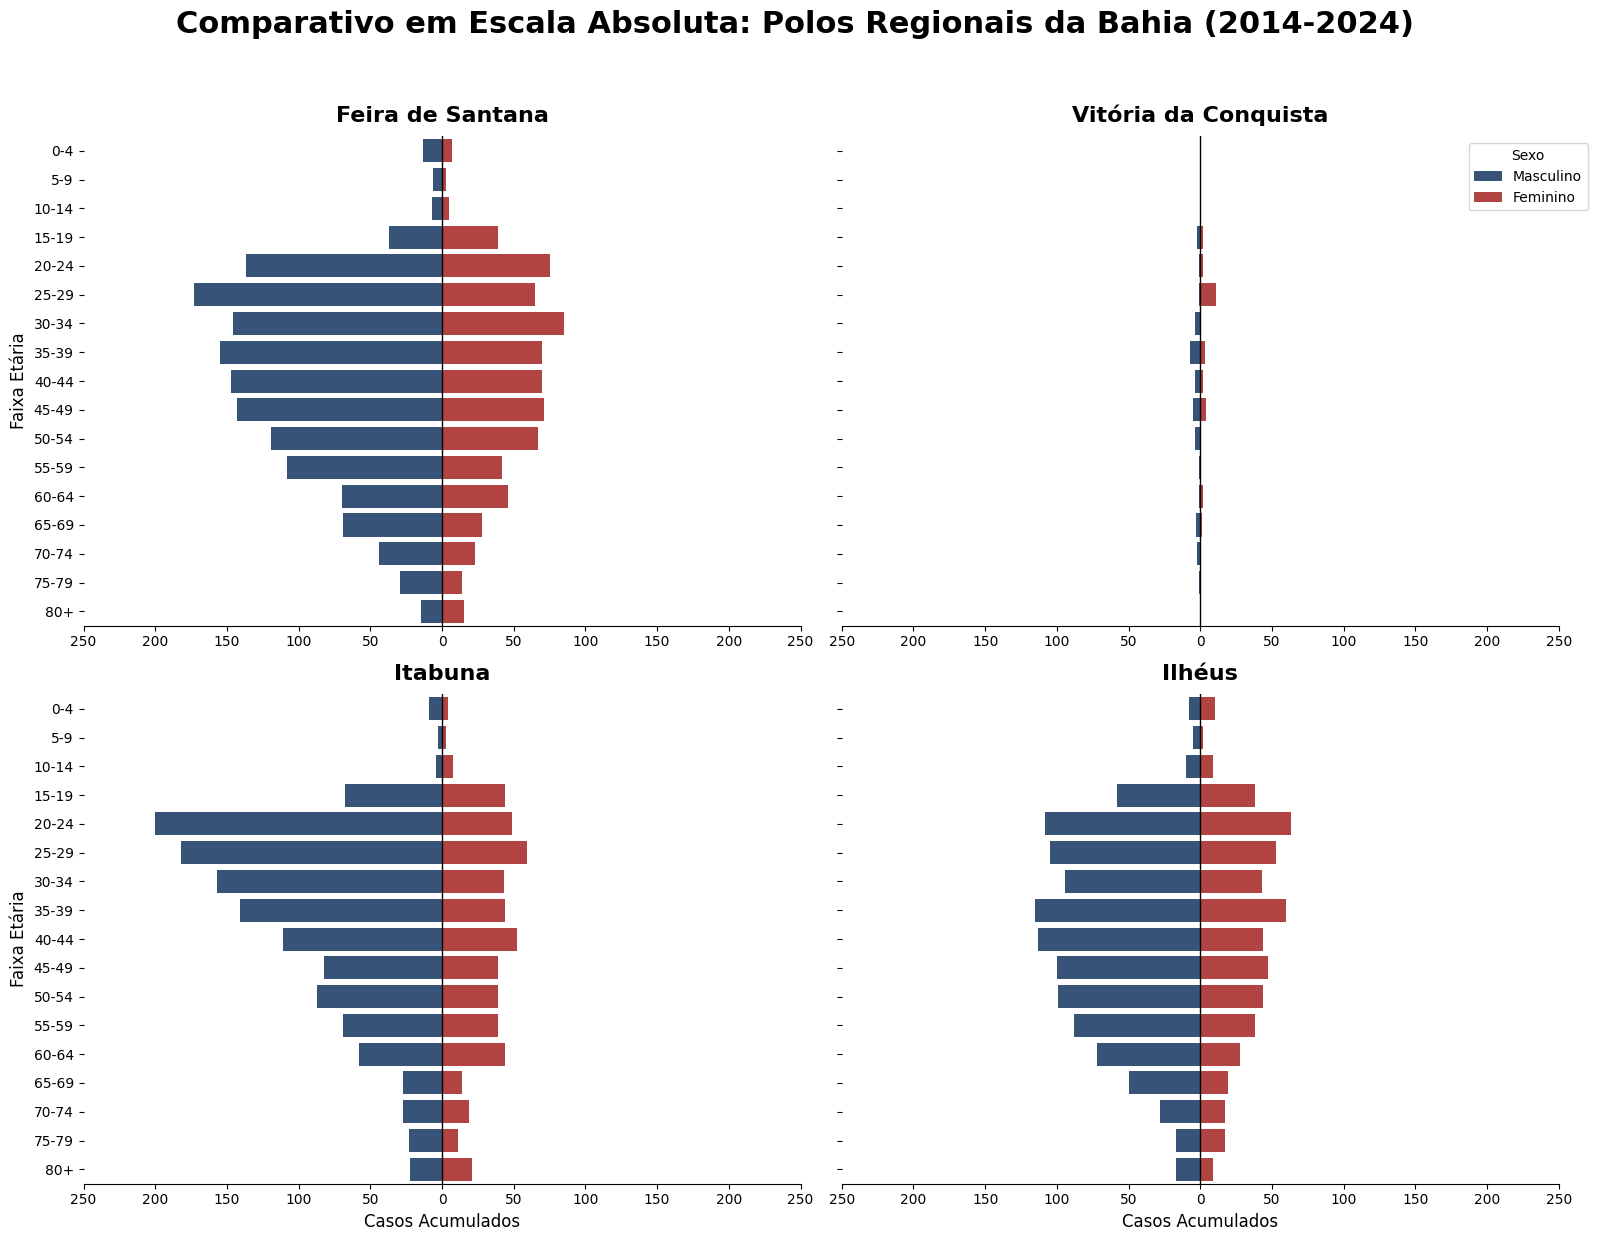

In [7]:
# ==============================================================================
# PAINEL 2: INTERIOR DA BAHIA 
# ==============================================================================
interior_ba = ['Feira de Santana', 'Vitória da Conquista', 'Itabuna', 'Ilhéus']
df_interior = df_piramide[df_piramide['Cidade'].isin(interior_ba)]

# DESCOBRINDO O MAIOR VALOR GLOBAL DO INTERIOR PARA TRAVAR O EIXO X
piramide_geral_interior = df_interior.groupby(['Cidade', 'Faixa_Etaria', 'Sexo'], observed=False).size().reset_index(name='Casos')
limite_global_interior = piramide_geral_interior['Casos'].max() * 1.1 

# Criando figura 2x2
fig, axes = plt.subplots(2, 2, figsize=(16, 12), sharey=True)
axes = axes.flatten()

for i, cidade in enumerate(interior_ba):
    ax = axes[i]
    df_cidade = df_interior[df_interior['Cidade'] == cidade]
    
    if not df_cidade.empty:
        piramide = df_cidade.groupby(['Faixa_Etaria', 'Sexo'], observed=False).size().reset_index(name='Casos')
        piramide.loc[piramide['Sexo'] == 'Masculino', 'Casos'] *= -1
        
        sns.barplot(x='Casos', y='Faixa_Etaria', data=piramide[piramide['Sexo'] == 'Masculino'], 
                    color='#2c5282', label='Masculino', ax=ax, errorbar=None)
        sns.barplot(x='Casos', y='Faixa_Etaria', data=piramide[piramide['Sexo'] == 'Feminino'], 
                    color='#c53030', label='Feminino', ax=ax, errorbar=None)

        # Trava todos na mesma escala do maior município do interior
        ax.set_xlim(-limite_global_interior, limite_global_interior)

        ticks = ax.get_xticks()
        ax.set_xticks(ticks)
        ax.set_xticklabels([int(abs(x)) for x in ticks])
        
    ax.set_title(f'{cidade}', fontsize=16, fontweight='bold', pad=10)
    ax.axvline(0, color='black', linewidth=1)
    
    # Textos dos eixos apenas nas bordas do grid
    ax.set_xlabel('Casos Acumulados' if i >= 2 else '', fontsize=12)
    ax.set_ylabel('Faixa Etária' if i % 2 == 0 else '', fontsize=12)
    
    if ax.get_legend(): ax.legend_.remove()
    if i == 1:
        ax.legend(title='Sexo', loc='upper right', bbox_to_anchor=(1.05, 1))

plt.suptitle('Comparativo em Escala Absoluta: Polos Regionais da Bahia (2014-2024)', fontsize=22, fontweight='bold', y=1.03)
sns.despine(left=True)
plt.tight_layout()
plt.show()

### Com base no último Censo Demográfico do IBGE (2022), a população oficial desses municípios baianos é:

#### Feira de Santana: 616.272 habitantes
#### Vitória da Conquista: 370.879 habitantes
#### Itabuna: 186.708 habitantes
#### Ilhéus: 178.703 habitantes

#### Vitória da Conquista praticamente não apresenta casos de tuberculose, para uma cidade de 380 mil habitantes é um dados provavelmente incorreto, apontando inconsistencia nos dados.

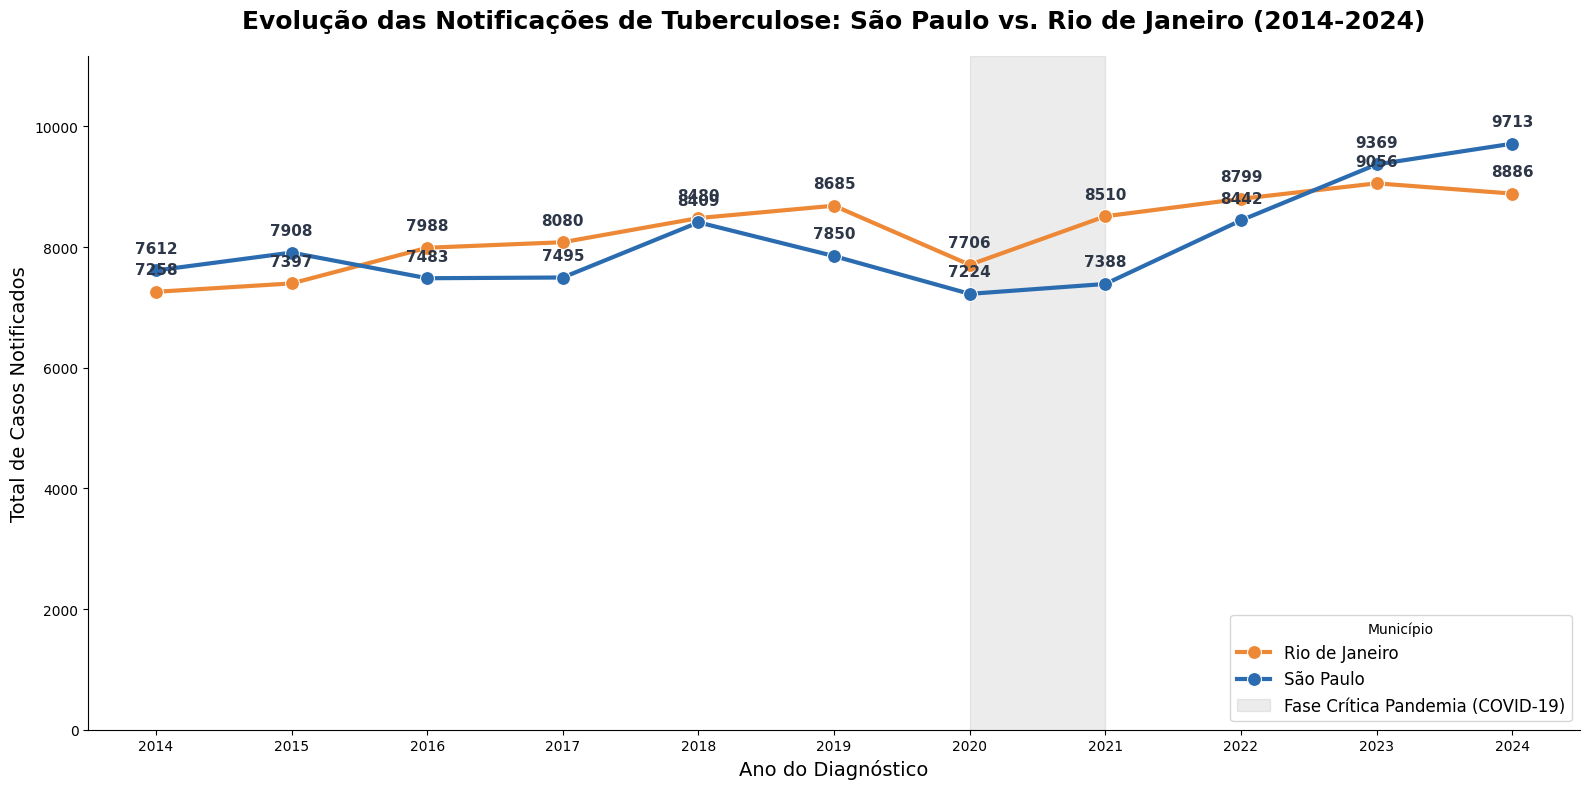

In [12]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. PREPARAÇÃO DOS DADOS
# Assumindo que o dataframe 'df' já é a sua base OURO (tuberculose_10_cidades_final.csv)
# Se a Data não estiver como datetime, convertemos:
if not pd.api.types.is_datetime64_any_dtype(df['Data_Diagnostico']):
    df['Data_Diagnostico'] = pd.to_datetime(df['Data_Diagnostico'], errors='coerce')

# Filtramos apenas as Megacidades usando a coluna padronizada
df_cidades = df[df['Cidade'].isin(['São Paulo', 'Rio de Janeiro'])].copy()

df_cidades['Ano_Diagnostico'] = df_cidades['Data_Diagnostico'].dt.year
df_temporal = df_cidades[(df_cidades['Ano_Diagnostico'] >= 2014) & (df_cidades['Ano_Diagnostico'] <= 2024)].copy()

# Agrupa por Ano e Cidade
evolucao_municipio = df_temporal.groupby(['Ano_Diagnostico', 'Cidade']).size().reset_index(name='Casos')

# 2. PLOTAGEM DO GRÁFICO
fig, ax = plt.subplots(figsize=(16, 8))

# Cores distintas: Azul para RJ e Laranja para SP (ou vice-versa, dependendo da ordem)
sns.lineplot(data=evolucao_municipio, x='Ano_Diagnostico', y='Casos', 
             hue='Cidade', palette=['#ed8936', '#2b6cb0'], 
             marker='o', markersize=10, linewidth=3, ax=ax)

# Marcação do período crítico da Pandemia
ax.axvspan(2020, 2021, color='gray', alpha=0.15, label='Fase Crítica Pandemia (COVID-19)')

# Acabamentos visuais
ax.set_title('Evolução das Notificações de Tuberculose: São Paulo vs. Rio de Janeiro (2014-2024)', 
             fontsize=18, fontweight='bold', pad=20)
ax.set_xlabel('Ano do Diagnóstico', fontsize=14)
ax.set_ylabel('Total de Casos Notificados', fontsize=14)
ax.set_xticks(range(2014, 2025))

# --- NOVIDADE: MARGEM DINÂMICA PARA NÚMEROS GIGANTES ---
offset = evolucao_municipio['Casos'].max() * 0.025 # Adiciona 2.5% de margem no topo da barra

for line in range(evolucao_municipio.shape[0]):
    ax.text(evolucao_municipio['Ano_Diagnostico'].iloc[line], 
            evolucao_municipio['Casos'].iloc[line] + offset, 
            f"{int(evolucao_municipio['Casos'].iloc[line])}", 
            ha='center', va='bottom', fontsize=11, fontweight='bold', color='#2d3748')

# Ajuste do limite Y para o número mais alto não cortar no teto do gráfico
ax.set_ylim(0, evolucao_municipio['Casos'].max() * 1.15)

# Legenda
handles, labels = ax.get_legend_handles_labels()
plt.legend(handles=handles, labels=labels, title='Município', loc='lower right', fontsize=12)
sns.despine()
plt.tight_layout()

plt.show()

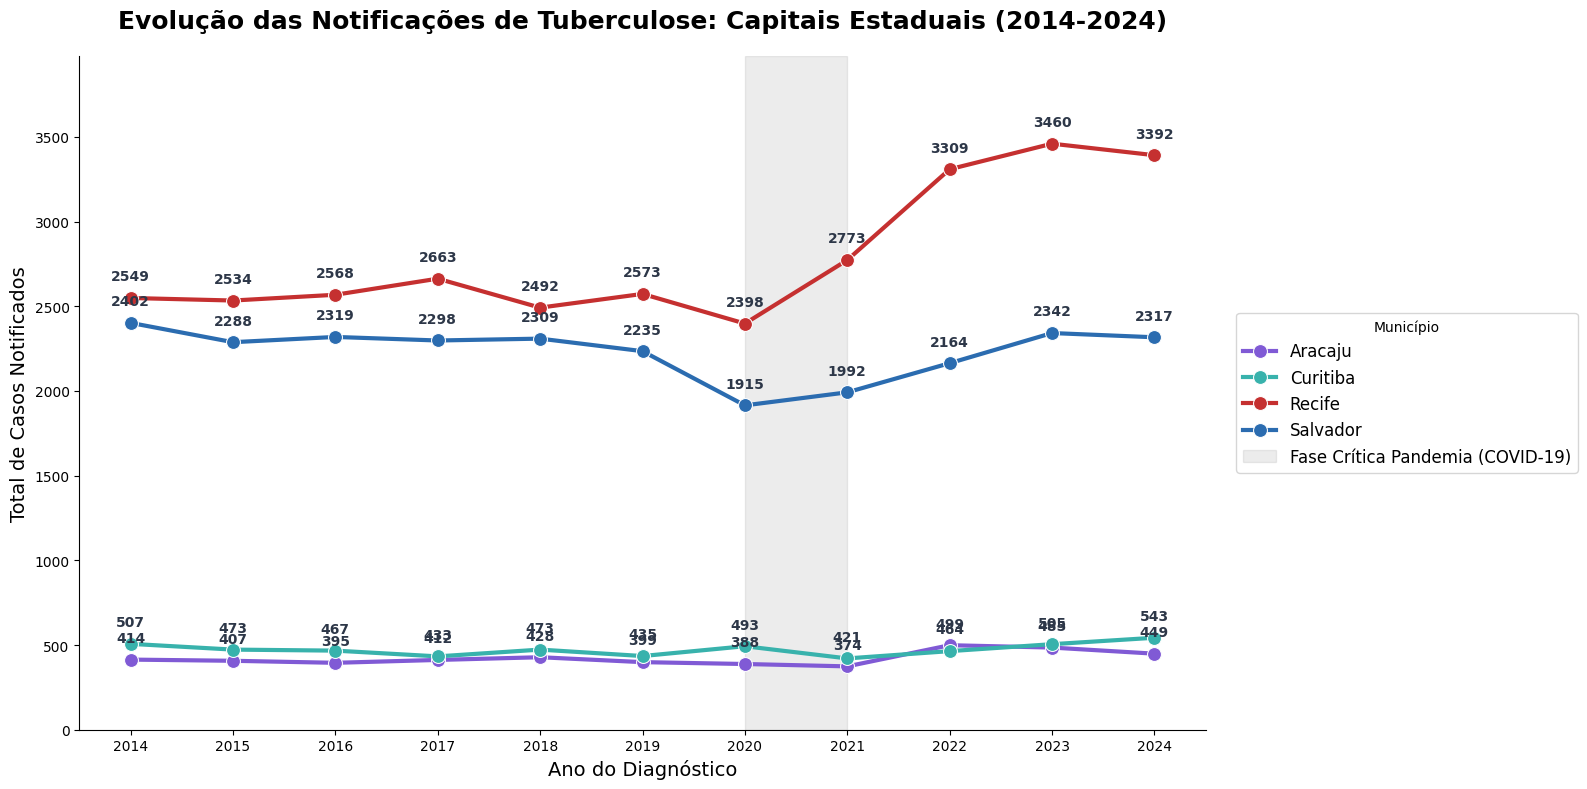

In [11]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. PREPARAÇÃO DOS DADOS
if not pd.api.types.is_datetime64_any_dtype(df['Data_Diagnostico']):
    df['Data_Diagnostico'] = pd.to_datetime(df['Data_Diagnostico'], errors='coerce')

# Filtramos as Capitais Estaduais (exceto as duas mega metrópoles)
capitais_estaduais = ['Salvador', 'Recife', 'Curitiba', 'Aracaju']
df_capitais = df[df['Cidade'].isin(capitais_estaduais)].copy()

df_capitais['Ano_Diagnostico'] = df_capitais['Data_Diagnostico'].dt.year
df_temporal_cap = df_capitais[(df_capitais['Ano_Diagnostico'] >= 2014) & (df_capitais['Ano_Diagnostico'] <= 2024)].copy()

# Agrupa por Ano e Cidade
evolucao_capitais = df_temporal_cap.groupby(['Ano_Diagnostico', 'Cidade']).size().reset_index(name='Casos')

# 2. PLOTAGEM DO GRÁFICO
fig, ax = plt.subplots(figsize=(16, 8))

# Paleta com 4 cores fortes e distintas para facilitar a diferenciação
paleta_cores = {'Salvador': '#2b6cb0', 'Recife': '#c53030', 'Curitiba': '#38b2ac', 'Aracaju': '#805ad5'}

sns.lineplot(data=evolucao_capitais, x='Ano_Diagnostico', y='Casos', 
             hue='Cidade', palette=paleta_cores, 
             marker='o', markersize=10, linewidth=3, ax=ax)

# Marcação do período crítico da Pandemia
ax.axvspan(2020, 2021, color='gray', alpha=0.15, label='Fase Crítica Pandemia (COVID-19)')

# Acabamentos visuais
ax.set_title('Evolução das Notificações de Tuberculose: Capitais Estaduais (2014-2024)', 
             fontsize=18, fontweight='bold', pad=20)
ax.set_xlabel('Ano do Diagnóstico', fontsize=14)
ax.set_ylabel('Total de Casos Notificados', fontsize=14)
ax.set_xticks(range(2014, 2025))

# Margem Dinâmica adaptada ao volume deste grupo
offset = evolucao_capitais['Casos'].max() * 0.025 

for line in range(evolucao_capitais.shape[0]):
    ax.text(evolucao_capitais['Ano_Diagnostico'].iloc[line], 
            evolucao_capitais['Casos'].iloc[line] + offset, 
            f"{int(evolucao_capitais['Casos'].iloc[line])}", 
            ha='center', va='bottom', fontsize=10, fontweight='bold', color='#2d3748')

# Ajuste do limite Y 
ax.set_ylim(0, evolucao_capitais['Casos'].max() * 1.15)

# Legenda jogada para fora do gráfico para não sobrepor as 4 linhas
handles, labels = ax.get_legend_handles_labels()
plt.legend(handles=handles, labels=labels, title='Município', loc='center left', bbox_to_anchor=(1.02, 0.5), fontsize=12)
sns.despine()
plt.tight_layout()

plt.show()

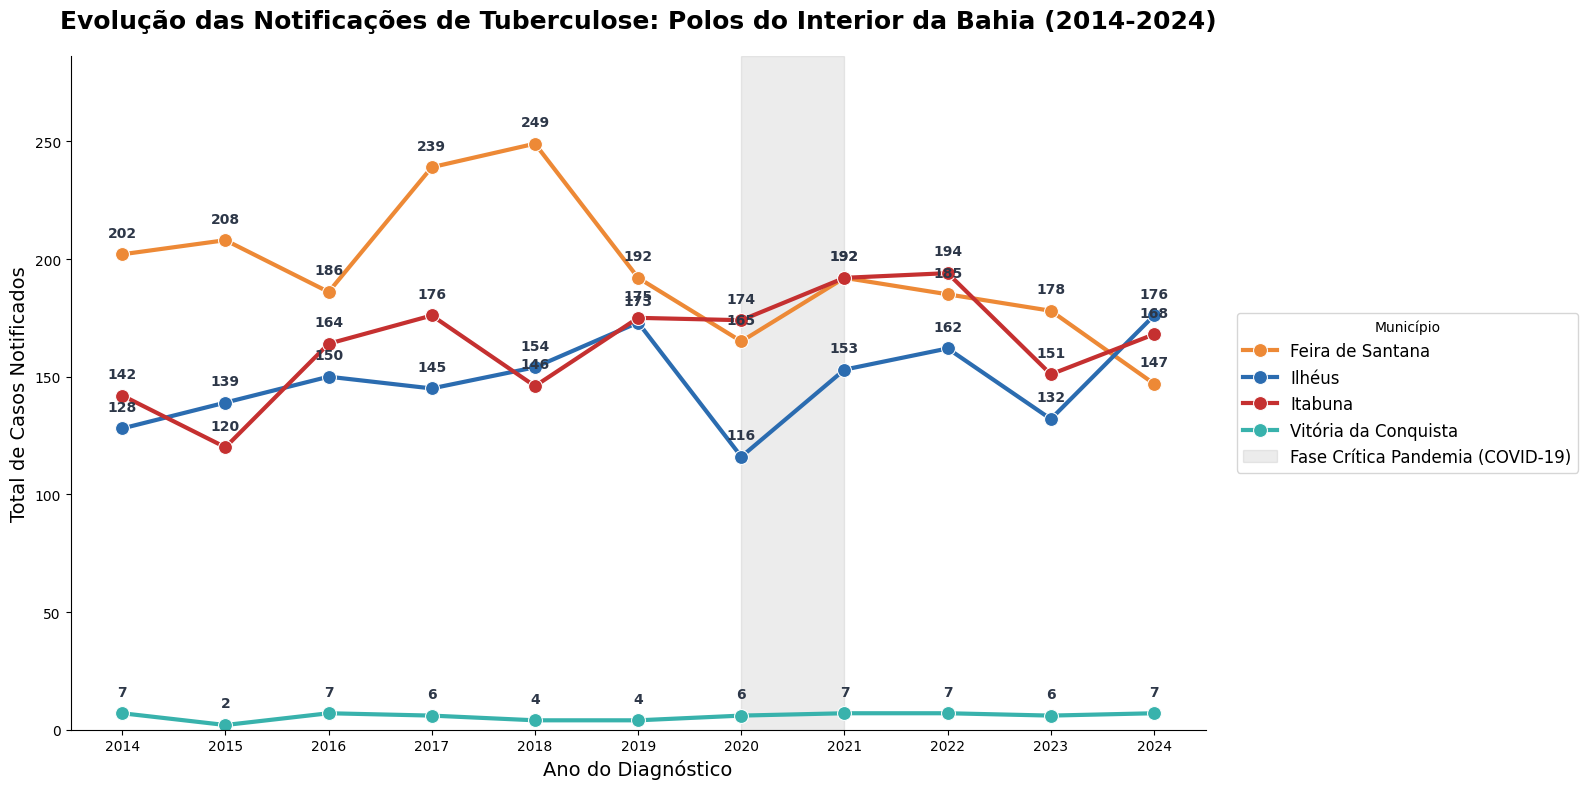

In [13]:
if not pd.api.types.is_datetime64_any_dtype(df['Data_Diagnostico']):
    df['Data_Diagnostico'] = pd.to_datetime(df['Data_Diagnostico'], errors='coerce')

# Filtramos os Polos Regionais da Bahia
interior_ba = ['Feira de Santana', 'Vitória da Conquista', 'Itabuna', 'Ilhéus']
df_interior = df[df['Cidade'].isin(interior_ba)].copy()

df_interior['Ano_Diagnostico'] = df_interior['Data_Diagnostico'].dt.year
df_temporal_int = df_interior[(df_interior['Ano_Diagnostico'] >= 2014) & (df_interior['Ano_Diagnostico'] <= 2024)].copy()

# Agrupa por Ano e Cidade
evolucao_interior = df_temporal_int.groupby(['Ano_Diagnostico', 'Cidade']).size().reset_index(name='Casos')

# 2. PLOTAGEM DO GRÁFICO
fig, ax = plt.subplots(figsize=(16, 8))

# Paleta com 4 cores para destacar cada polo regional
paleta_cores = {'Feira de Santana': '#ed8936', 'Vitória da Conquista': '#38b2ac', 
                'Itabuna': '#c53030', 'Ilhéus': '#2b6cb0'}

sns.lineplot(data=evolucao_interior, x='Ano_Diagnostico', y='Casos', 
             hue='Cidade', palette=paleta_cores, 
             marker='o', markersize=10, linewidth=3, ax=ax)

# Marcação do período crítico da Pandemia
ax.axvspan(2020, 2021, color='gray', alpha=0.15, label='Fase Crítica Pandemia (COVID-19)')

# Acabamentos visuais
ax.set_title('Evolução das Notificações de Tuberculose: Polos do Interior da Bahia (2014-2024)', 
             fontsize=18, fontweight='bold', pad=20)
ax.set_xlabel('Ano do Diagnóstico', fontsize=14)
ax.set_ylabel('Total de Casos Notificados', fontsize=14)
ax.set_xticks(range(2014, 2025))

# Margem Dinâmica adaptada ao volume do interior
offset = evolucao_interior['Casos'].max() * 0.025 

for line in range(evolucao_interior.shape[0]):
    ax.text(evolucao_interior['Ano_Diagnostico'].iloc[line], 
            evolucao_interior['Casos'].iloc[line] + offset, 
            f"{int(evolucao_interior['Casos'].iloc[line])}", 
            ha='center', va='bottom', fontsize=10, fontweight='bold', color='#2d3748')

# Ajuste do limite Y 
ax.set_ylim(0, evolucao_interior['Casos'].max() * 1.15)

# Legenda jogada para fora do gráfico
handles, labels = ax.get_legend_handles_labels()
plt.legend(handles=handles, labels=labels, title='Município', loc='center left', bbox_to_anchor=(1.02, 0.5), fontsize=12)
sns.despine()
plt.tight_layout()

plt.show()

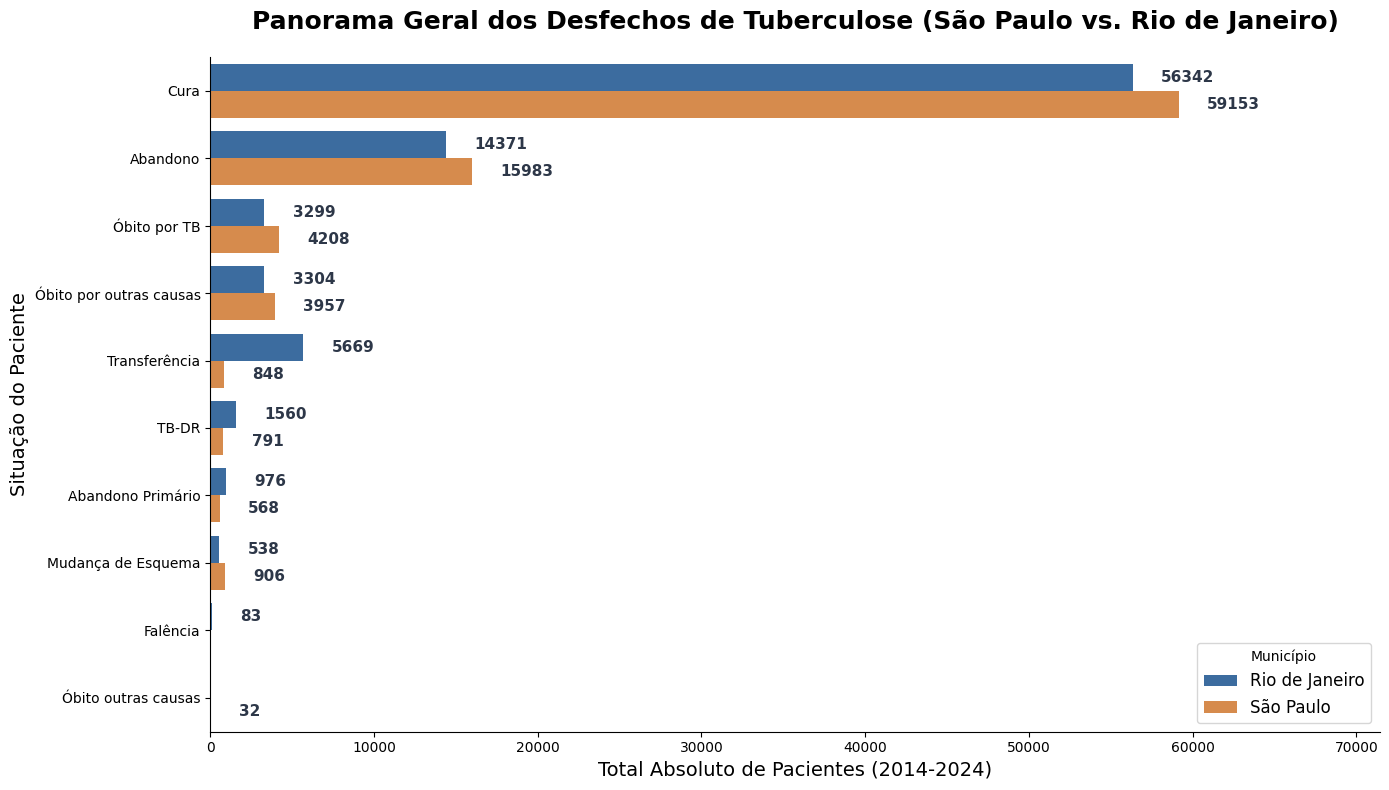

In [16]:
megacidades = ['São Paulo', 'Rio de Janeiro']
df_analise = df[df['Cidade'].isin(megacidades)].copy()

# --- CORREÇÃO DA TIPAGEM DOS DESFECHOS (Blindagem contra erros do SUS) ---
mapa_desfechos = {
    1: 'Cura', 2: 'Abandono', 3: 'Óbito por TB', 
    4: 'Óbito outras causas', 5: 'Transferência', 
    6: 'Mudança Diagnóstico', 7: 'TB-DR (Resistente)', 
    8: 'Mudança Esquema', 9: 'Falência', 10: 'Abandono Primário'
}

def padronizar_desfecho(valor):
    if pd.isna(valor):
        return None
    
    # Tenta transformar o valor matemático ('03', '3.0', '4') no número limpo
    try:
        codigo = int(float(valor))
        if codigo in mapa_desfechos:
            return mapa_desfechos[codigo]
        elif codigo == 0:
            return None # '0' é ausência de informação, vira nulo para não sujar o gráfico
        else:
            return str(valor)
    except ValueError:
        # Se der erro matemático, é porque o valor já é texto (ex: 'Cura'). Retorna ele mesmo.
        return valor

# Aplica a função de faxina
df_analise['Desfecho_Clinico'] = df_analise['Situacao_Encerramento_Final'].apply(padronizar_desfecho)

# Removemos os nulos e os zeros que acabamos de anular
df_analise = df_analise.dropna(subset=['Desfecho_Clinico'])

# 2. PLOTAGEM DO GRÁFICO
fig, ax = plt.subplots(figsize=(14, 8))

# Define a ordem do maior para o menor
ordem_desfechos = df_analise['Desfecho_Clinico'].value_counts().index

# Cores: Azul para SP, Laranja para RJ
sns.countplot(data=df_analise, 
              y='Desfecho_Clinico', 
              hue='Cidade', 
              palette=['#2b6cb0', '#ed8936'],
              order=ordem_desfechos,
              ax=ax)

ax.set_title('Panorama Geral dos Desfechos de Tuberculose (São Paulo vs. Rio de Janeiro)', 
             fontsize=18, fontweight='bold', pad=20)
ax.set_xlabel('Total Absoluto de Pacientes (2014-2024)', fontsize=14)
ax.set_ylabel('Situação do Paciente', fontsize=14)

# Rótulos nas barras
maior_barra = df_analise['Desfecho_Clinico'].value_counts().max()

for p in ax.patches:
    largura = p.get_width()
    if not pd.isna(largura) and largura > 0:
        ax.text(largura + (maior_barra * 0.015), 
                p.get_y() + p.get_height() / 2, 
                f'{int(largura)}', 
                va='center', fontsize=11, fontweight='bold', color='#2d3748')

# Aumenta o eixo X em 15% para que o número de curas não corte no canto da tela
ax.set_xlim(0, ax.get_xlim()[1] * 1.15)

plt.legend(title='Município', loc='lower right', fontsize=12)
sns.despine()
plt.tight_layout()

plt.show()

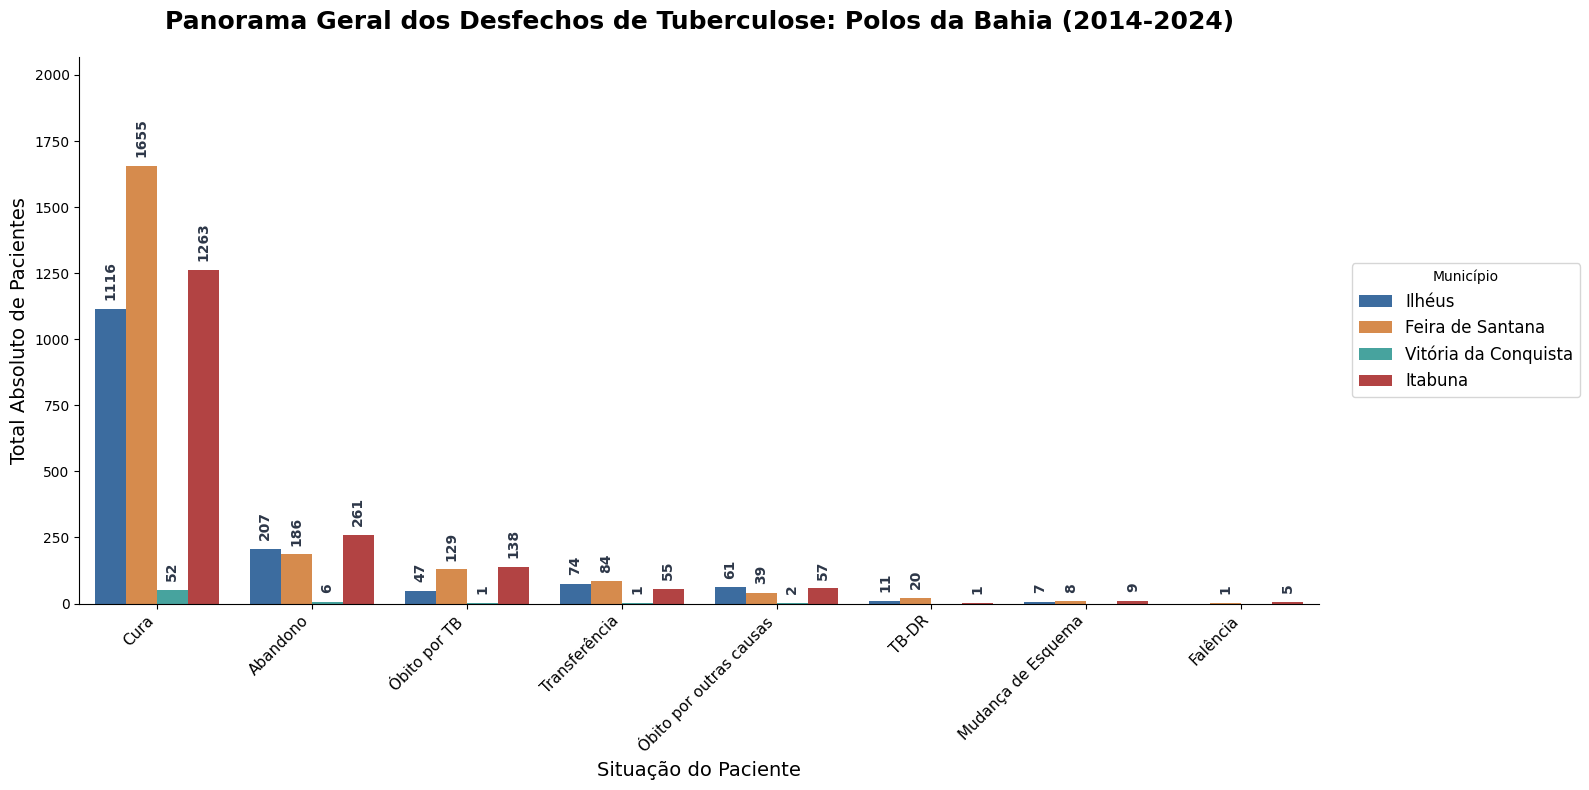

In [19]:
polos_bahia = ['Feira de Santana', 'Vitória da Conquista', 'Itabuna', 'Ilhéus']
df_analise_ba = df[df['Cidade'].isin(polos_bahia)].copy()

# Função blindada para corrigir os erros do SUS (0, 03, 04)
mapa_desfechos = {
    1: 'Cura', 2: 'Abandono', 3: 'Óbito por TB', 
    4: 'Óbito outras causas', 5: 'Transferência', 
    6: 'Mudança Diagnóstico', 7: 'TB-DR (Resistente)', 
    8: 'Mudança Esquema', 9: 'Falência', 10: 'Abandono Primário'
}

def padronizar_desfecho(valor):
    if pd.isna(valor):
        return None
    try:
        codigo = int(float(valor))
        if codigo in mapa_desfechos:
            return mapa_desfechos[codigo]
        elif codigo == 0:
            return None 
        else:
            return str(valor)
    except ValueError:
        return valor

# Aplica a faxina
df_analise_ba['Desfecho_Clinico'] = df_analise_ba['Situacao_Encerramento_Final'].apply(padronizar_desfecho)
df_analise_ba = df_analise_ba.dropna(subset=['Desfecho_Clinico'])

# 2. PLOTAGEM DO GRÁFICO (AGORA VERTICAL)
fig, ax = plt.subplots(figsize=(16, 8))

# Mantém a ordem decrescente focando no total de casos
ordem_desfechos = df_analise_ba['Desfecho_Clinico'].value_counts().index

paleta_cores = {'Feira de Santana': '#ed8936', 'Vitória da Conquista': '#38b2ac', 
                'Itabuna': '#c53030', 'Ilhéus': '#2b6cb0'}

# Trocamos y por x para fazer colunas verticais
sns.countplot(data=df_analise_ba, 
              x='Desfecho_Clinico', 
              hue='Cidade', 
              palette=paleta_cores,
              order=ordem_desfechos,
              ax=ax)

ax.set_title('Panorama Geral dos Desfechos de Tuberculose: Polos da Bahia (2014-2024)', 
             fontsize=18, fontweight='bold', pad=20)
ax.set_ylabel('Total Absoluto de Pacientes', fontsize=14)
ax.set_xlabel('Situação do Paciente', fontsize=14)

# Inclina os textos do eixo X em 45 graus para não encavalarem
plt.xticks(rotation=45, ha='right', fontsize=11)

# Descobre a altura máxima real gerada no gráfico para calcular a margem do texto
altura_maxima = max([p.get_height() for p in ax.patches if not pd.isna(p.get_height())])

# Adicionando os valores no topo das colunas
for p in ax.patches:
    altura = p.get_height()
    if not pd.isna(altura) and altura > 0:
        # Texto rotacionado em 90 graus (vertical) para caber na largura da coluna
        ax.text(p.get_x() + p.get_width() / 2, 
                altura + (altura_maxima * 0.02), 
                f'{int(altura)}', 
                ha='center', va='bottom', fontsize=10, fontweight='bold', color='#2d3748', rotation=90)

# Aumenta o teto do eixo Y para caberem os números verticais sem cortar
ax.set_ylim(0, altura_maxima * 1.25)

# Legenda jogada para fora do gráfico
handles, labels = ax.get_legend_handles_labels()
plt.legend(handles=handles, labels=labels, title='Município', loc='center left', bbox_to_anchor=(1.02, 0.5), fontsize=12)

sns.despine()
plt.tight_layout()

plt.show()